# Room Occupancy Estimation — training and evaluating five classifiers

Dataset: *Room Occupancy Estimation* (UCI Machine Learning Repository, id 864).
Goal: predict how many people (0–3) are in a room from non-intrusive sensor readings
(temperature, light, sound, CO2 and motion).

In [1]:
import sys
import time
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)

Python      : 3.10.12
scikit-learn: 1.7.2


## 1. Load the data

In [2]:
df = pd.read_csv("../data/Occupancy_Estimation.csv")
print("Shape:", df.shape)
assert df.shape == (10129, 19)

Shape: (10129, 19)


**Finding:** 10,129 rows × 19 columns — `Date`, `Time`, 16 sensor readings and the target `Room_Occupancy_Count`.

## 2. Inspect

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10129 entries, 0 to 10128
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  10129 non-null  object 
 1   Time                  10129 non-null  object 
 2   S1_Temp               10129 non-null  float64
 3   S2_Temp               10129 non-null  float64
 4   S3_Temp               10129 non-null  float64
 5   S4_Temp               10129 non-null  float64
 6   S1_Light              10129 non-null  int64  
 7   S2_Light              10129 non-null  int64  
 8   S3_Light              10129 non-null  int64  
 9   S4_Light              10129 non-null  int64  
 10  S1_Sound              10129 non-null  float64
 11  S2_Sound              10129 non-null  float64
 12  S3_Sound              10129 non-null  float64
 13  S4_Sound              10129 non-null  float64
 14  S5_CO2                10129 non-null  int64  
 15  S5_CO2_Slope       

In [4]:
df.head()

,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
S1_Temp,10129.0,25.454012,0.351351,24.940000,25.190000,25.38,25.63,26.380000
S2_Temp,10129.0,25.546059,0.586325,24.750000,25.190000,25.38,25.63,29.000000
S3_Temp,10129.0,25.056621,0.427283,24.440000,24.690000,24.94,25.38,26.190000
S4_Temp,10129.0,25.754125,0.356434,24.940000,25.440000,25.75,26.00,26.560000
S1_Light,10129.0,25.445059,51.011264,0.000000,0.000000,0.00,12.00,165.000000
S2_Light,10129.0,26.016290,67.304170,0.000000,0.000000,0.00,14.00,258.000000
S3_Light,10129.0,34.248494,58.400744,0.000000,0.000000,0.00,50.00,280.000000
S4_Light,10129.0,13.220259,19.602219,0.000000,0.000000,0.00,22.00,74.000000
S1_Sound,10129.0,0.168178,0.316709,0.060000,0.070000,0.08,0.08,3.880000
S2_Sound,10129.0,0.120066,0.266503,0.040000,0.050000,0.05,0.06,3.440000


In [6]:
light_cols = ["S1_Light", "S2_Light", "S3_Light", "S4_Light"]
print("Share of rows where the light reading is exactly 0:")
print((df[light_cols] == 0).mean().round(3))
print()
print("Days covered:", df["Date"].nunique(), "->", df["Date"].min(), "to", df["Date"].max())

Share of rows where the light reading is exactly 0:
S1_Light    0.577
S2_Light    0.577
S3_Light    0.552
S4_Light    0.553
dtype: float64

Days covered: 7 -> 2017/12/22 to 2018/01/11


**Findings**

- Only `Date` and `Time` are text. The 16 sensor columns are numeric (9 float, 7 integer), the target is an integer 0–3.
- The scales are very different: temperatures sit in a narrow 24.4–29.0 °C band (std 0.35–0.59), light goes 0–280 lux, sound (amplifier output in volts) is mostly below 0.1 (max 3.88), CO2 is 345–1,270 ppm, the CO2 slope runs from −6.3 to 9.0 and the two PIR motion sensors are 0/1. Distance- and gradient-based models (KNN, SVM, Logistic Regression) need these on a common scale.
- Light is mostly zero: the median of all four light sensors is 0, and each reads exactly 0 in 55–58 % of rows — the empty room is usually dark.
- The readings fall on 7 dates (22–26 Dec 2017 and 10–11 Jan 2018), one row every 30–31 seconds.

## 3. Missing values

In [7]:
df.isnull().sum()

Date                    0
Time                    0
S1_Temp                 0
S2_Temp                 0
S3_Temp                 0
S4_Temp                 0
S1_Light                0
S2_Light                0
S3_Light                0
S4_Light                0
S1_Sound                0
S2_Sound                0
S3_Sound                0
S4_Sound                0
S5_CO2                  0
S5_CO2_Slope            0
S6_PIR                  0
S7_PIR                  0
Room_Occupancy_Count    0
dtype: int64

**Finding:** no missing values in any column, so no imputation is needed.

## 4. Class balance

In [8]:
TARGET = "Room_Occupancy_Count"
proportions = df[TARGET].value_counts(normalize=True).sort_index()
balance = pd.DataFrame({
    "rows": df[TARGET].value_counts().sort_index(),
    "percent": (proportions * 100).round(2),
})
balance

,rows,percent
Room_Occupancy_Count,,
0,8228,81.23
1,459,4.53
2,748,7.38
3,694,6.85


**Finding:** the classes are strongly imbalanced — 0 people 81.23 % (8,228 rows), 1 person 4.53 % (459), 2 people 7.38 % (748), 3 people 6.85 % (694). A model that always predicts "empty" would already get 81 % accuracy, so accuracy alone is not enough. I use a stratified split and report macro-averaged Precision/Recall/F1 plus MCC.

## 5. Exploratory plots

### 5a. Light and CO2 by occupancy count

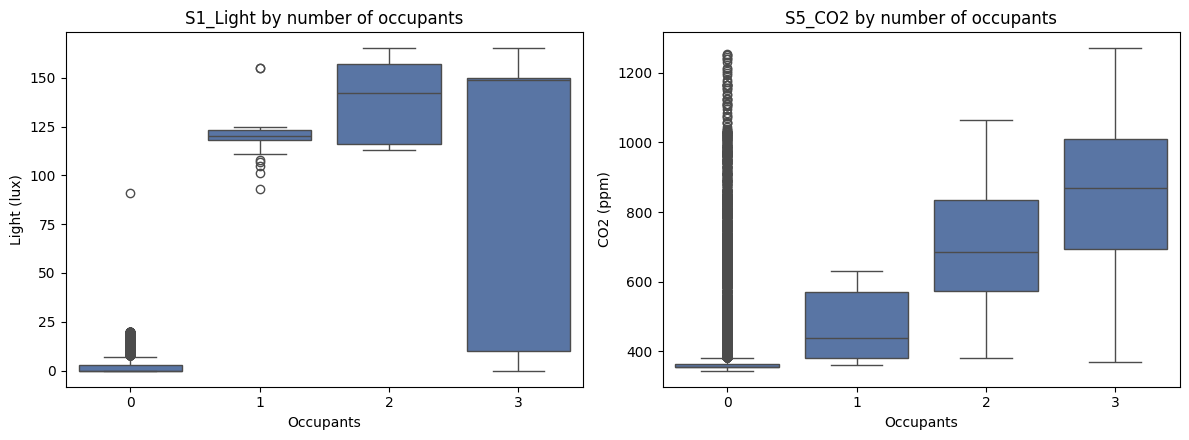

,S1_Light,S5_CO2
Room_Occupancy_Count,,
0,0.0,355.0
1,120.0,440.0
2,142.0,685.0
3,149.0,870.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x=TARGET, y="S1_Light", color="#4C72B0", ax=axes[0])
axes[0].set_title("S1_Light by number of occupants")
axes[0].set_xlabel("Occupants")
axes[0].set_ylabel("Light (lux)")
sns.boxplot(data=df, x=TARGET, y="S5_CO2", color="#4C72B0", ax=axes[1])
axes[1].set_title("S5_CO2 by number of occupants")
axes[1].set_xlabel("Occupants")
axes[1].set_ylabel("CO2 (ppm)")
plt.tight_layout()
plt.show()

df.groupby(TARGET)[["S1_Light", "S5_CO2"]].median()

In [10]:
# The empty-room CO2 box has a long tail of high values. Are those rooms that were just vacated?
lingering = df[(df[TARGET] == 0) & (df["S5_CO2"] > 500)]
print(f"Empty-room rows with CO2 above 500 ppm: {len(lingering)} of {(df[TARGET] == 0).sum()}")
print(f"Share of those where CO2 is falling (slope < 0): {(lingering['S5_CO2_Slope'] < 0).mean():.1%}")

Empty-room rows with CO2 above 500 ppm: 951 of 8228
Share of those where CO2 is falling (slope < 0): 91.1%


**Findings**

- **S1_Light** separates empty from occupied almost perfectly: the empty-room median is 0 lux against 120–149 lux when anyone is present. It separates 1, 2 and 3 people much less well; the 3-person box even stretches down to ~10 lux (S1's light is sometimes low even with three people present).
- **S5_CO2** rises with headcount (medians 355 → 440 → 685 → 870 ppm), but the 2- and 3-person boxes overlap. The empty class has a long tail of high CO2 values: 951 empty-room rows are above 500 ppm and 91 % of them have a falling CO2 slope, i.e. people have just left and the CO2 has not cleared yet. These rows can look "occupied" to a model that leans on CO2.

### 5b. Correlation heatmap

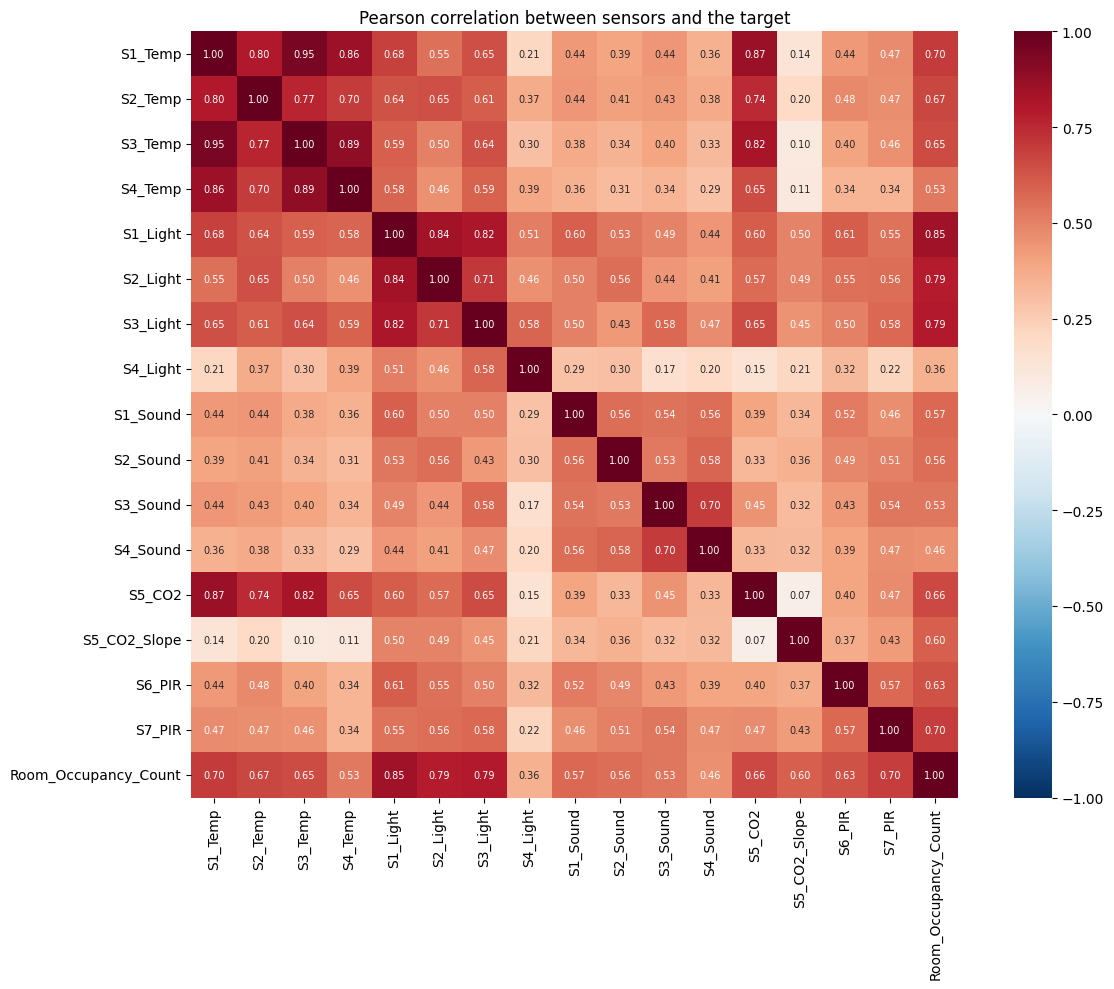

In [11]:
corr = df.drop(columns=["Date", "Time"]).corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.title("Pearson correlation between sensors and the target")
plt.tight_layout()
plt.show()

In [12]:
temp_cols = ["S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"]
print("Correlation among the four temperature sensors:")
print(corr.loc[temp_cols, temp_cols].round(3))
print()
print("Correlation of each sensor with the target:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

Correlation among the four temperature sensors:
         S1_Temp  S2_Temp  S3_Temp  S4_Temp
S1_Temp    1.000    0.800    0.949    0.855
S2_Temp    0.800    1.000    0.766    0.697
S3_Temp    0.949    0.766    1.000    0.885
S4_Temp    0.855    0.697    0.885    1.000

Correlation of each sensor with the target:
S1_Light        0.849
S3_Light        0.793
S2_Light        0.789
S1_Temp         0.701
S7_PIR          0.695
S2_Temp         0.671
S5_CO2          0.660
S3_Temp         0.652
S6_PIR          0.633
S5_CO2_Slope    0.601
S1_Sound        0.574
S2_Sound        0.558
S3_Sound        0.532
S4_Temp         0.527
S4_Sound        0.460
S4_Light        0.356
Name: Room_Occupancy_Count, dtype: float64


**Findings**

- The four temperature sensors are strongly correlated with each other (0.70–0.95; S1 vs S3 = 0.95). Gaussian Naive Bayes assumes features are independent given the class, so it effectively counts the same temperature signal four times. I test whether this hurts it in section 10d.
- The light sensors have the strongest correlation with the target (S1_Light 0.85, S3_Light 0.79, S2_Light 0.79), followed by S1_Temp (0.70), S7_PIR (0.70) and S2_Temp (0.67). The light sensors are also correlated with each other (S1–S2 0.84, S1–S3 0.82).

## 6. Clean the data

In [13]:
df_model = df.drop(columns=["Date", "Time"])
print("Columns left:", df_model.shape[1])
print("Rows whose 16 sensor values + label duplicate another row:", df_model.duplicated().sum())

Columns left: 17
Rows whose 16 sensor values + label duplicate another row: 1301


**Why `Date` and `Time` are dropped:** they record *when* a reading was taken, not *what* the sensors measured. The data comes from one room over only 7 dates, so a model given the timestamp could learn the schedule ("people were in the room at 11:00 on 22 Dec") instead of the sensor patterns, and that would not carry over to any other day or room.

After dropping them, 1,301 rows repeat the sensor values and label of another row. They are genuine consecutive readings of an unchanged room, so I keep them, but they matter for the split below.

## 7. Features, target and train/test split

In [14]:
from sklearn.model_selection import train_test_split

FEATURES = [c for c in df_model.columns if c != TARGET]
X = df_model[FEATURES]
y = df_model[TARGET]
print(len(FEATURES), "features:", FEATURES)

RANDOM_STATE = 55
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test :", X_test.shape, " y_test :", y_test.shape)

16 features: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']
X_train: (8103, 16)  y_train: (8103,)
X_test : (2026, 16)  y_test : (2026,)


In [15]:
split_check = pd.DataFrame({
    "full %": (y.value_counts(normalize=True).sort_index() * 100).round(2),
    "train %": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "test %": (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
})
split_check

,full %,train %,test %
Room_Occupancy_Count,,,
0,81.23,81.23,81.24
1,4.53,4.53,4.54
2,7.38,7.39,7.35
3,6.85,6.85,6.86


In [16]:
# Readings are taken every ~30 s, so many rows are repeats. How many test rows
# have an identical twin in the training set?
twins = X_test.merge(X_train.drop_duplicates(), how="left", indicator=True)["_merge"].eq("both").sum()
print(f"Test rows with an identical feature row in train: {twins} of {len(X_test)} ({twins / len(X_test):.1%})")

Test rows with an identical feature row in train: 352 of 2026 (17.4%)


**Findings**

- 8,103 training rows and 2,026 test rows (80/20), `random_state=55`.
- Thanks to `stratify=y`, the class proportions in train and test match the full data to within 0.05 percentage points.
- **Caveat:** 352 of the 2,026 test rows (17.4 %) have an identical twin in the training set, and many more are near-identical neighbours recorded 30 seconds apart. A random split of time-series data therefore gives optimistic scores; testing on completely unseen days would be harder. All test scores below should be read with that in mind.

## 8. Save the held-out test set for the Streamlit app

In [17]:
test_df = X_test.copy()
test_df[TARGET] = y_test
test_df.to_csv("../test_data.csv", index=False)

reloaded = pd.read_csv("../test_data.csv")
print("test_data.csv shape:", reloaded.shape)
print("Columns:", list(reloaded.columns))
assert reloaded.shape == (len(X_test), 17)
assert "Unnamed: 0" not in reloaded.columns

test_data.csv shape: (2026, 17)
Columns: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count']


**Finding:** `test_data.csv` has 2,026 rows and 17 columns (the 16 sensor features + `Room_Occupancy_Count`) and no extra index column. This is the file to upload in the Streamlit app.

## 9. Build one pipeline per model

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, cross_val_score


def scaled(clf):
    """StandardScaler followed by the classifier."""
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])

Every model is `StandardScaler` → classifier inside one `Pipeline`. The scaler is therefore fitted on the training data only and is saved inside each `.pkl`, so the app does not need a separate scaler file.

Scaling matters for Logistic Regression (optimisation and regularisation), KNN (Euclidean distance) and SVM (RBF kernel distance). It does not change the Decision Tree: a split threshold on a standardised feature puts the rows in exactly the same branches. I keep the scaler there anyway so all five pipelines have the same structure.

## 10. Hyper-parameter search (5-fold CV on the training set only)

Three models get a grid search. Selection metric is macro-F1 so the small classes
(1, 2 and 3 people) matter as much as the empty-room class. Accuracy is recorded alongside.

In [19]:
scoring = {"f1_macro": "f1_macro", "accuracy": "accuracy"}


def run_search(pipe, grid):
    search = GridSearchCV(pipe, grid, cv=5, scoring=scoring, refit="f1_macro",
                          return_train_score=True, n_jobs=-1)
    search.fit(X_train, y_train)
    return search


def cv_table(search, param):
    res = pd.DataFrame(search.cv_results_)
    table = res[[f"param_{param}", "mean_train_accuracy", "mean_test_accuracy",
                 "mean_train_f1_macro", "mean_test_f1_macro"]]
    table.columns = [param.replace("clf__", ""), "train acc", "CV acc", "train F1", "CV F1"]
    return table.round(4)

### 10a. Decision Tree — `max_depth`

In [20]:
tree_search = run_search(scaled(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                         {"clf__max_depth": [2, 3, 4, 5, 6, 8, 10, 15, None]})
print("Best:", tree_search.best_params_, " CV macro-F1 =", round(tree_search.best_score_, 4))
cv_table(tree_search, "clf__max_depth")

Best: {'clf__max_depth': 10}  CV macro-F1 = 0.9833


,max_depth,train acc,CV acc,train F1,CV F1
0,2,0.9332,0.9304,0.7300,0.7199
1,3,0.9670,0.9654,0.8823,0.8772
2,4,0.9904,0.9877,0.9647,0.9570
3,5,0.9939,0.9911,0.9769,0.9683
4,6,0.9961,0.9932,0.9858,0.9777
5,8,0.9990,0.9941,0.9961,0.9807
6,10,0.9999,0.9948,0.9996,0.9833
7,15,1.0000,0.9947,1.0000,0.9828
8,None,1.0000,0.9947,1.0000,0.9828


**Findings:** depths 2 and 3 underfit (CV macro-F1 0.720 and 0.877 — the tree cannot separate 1/2/3 people with so few splits). CV F1 climbs to its best at **max_depth = 10** (0.9833). Deeper trees (15 or unlimited) reach 100 % training accuracy but CV F1 drops slightly to 0.9828: the extra depth only memorises the training rows. The overfitting is mild because light and CO2 separate the classes well, but there is no gain beyond depth 10, so I use 10.

### 10b. KNN — `n_neighbors`

In [21]:
knn_search = run_search(scaled(KNeighborsClassifier()),
                        {"clf__n_neighbors": [3, 5, 7, 11, 15, 21]})
print("Best:", knn_search.best_params_, " CV macro-F1 =", round(knn_search.best_score_, 4))
cv_table(knn_search, "clf__n_neighbors")

Best: {'clf__n_neighbors': 3}  CV macro-F1 = 0.9708


,n_neighbors,train acc,CV acc,train F1,CV F1
0,3,0.9958,0.9915,0.9854,0.9708
1,5,0.9943,0.9910,0.9800,0.9687
2,7,0.9927,0.9894,0.9749,0.9633
3,11,0.9902,0.9885,0.9663,0.9605
4,15,0.9892,0.9880,0.9629,0.9584
5,21,0.9879,0.9869,0.9582,0.9543


In [22]:
# Same KNN without the scaler, to see how much scaling matters for a distance-based model
best_k = knn_search.best_params_["clf__n_neighbors"]
unscaled = cross_val_score(KNeighborsClassifier(n_neighbors=best_k), X_train, y_train,
                           cv=5, scoring="f1_macro")
with_scaler = cross_val_score(scaled(KNeighborsClassifier(n_neighbors=best_k)), X_train, y_train,
                              cv=5, scoring="f1_macro")
print(f"k={best_k}  CV macro-F1 without scaling: {unscaled.mean():.4f}")
print(f"k={best_k}  CV macro-F1 with scaling   : {with_scaler.mean():.4f}")

k=3  CV macro-F1 without scaling: 0.9860
k=3  CV macro-F1 with scaling   : 0.9708


**Findings**

- **k = 3** is best (CV macro-F1 0.9708). F1 falls steadily as k grows (0.9543 at k = 21) while accuracy falls much less (0.9915 → 0.9869): larger neighbourhoods let the big "empty" class and the neighbouring headcounts outvote the small classes near the class borders.
- **Scaling check — a surprise:** without the scaler, k = 3 scores *higher* (0.9860 vs 0.9708). Unscaled, the distance is dominated by CO2 (std ≈ 200) and light (std 20–67), which are the two strongest signals. After standardising, all 16 features count equally in the distance, including the four sound and four temperature sensors, which add noise. So scaling does matter for KNN, but here it hurts. I keep the scaler so that all pipelines follow the same pattern, and note feature selection/weighting as a possible improvement for KNN.

### 10c. SVM (RBF kernel) — `C`

`probability=True` makes every fit run an extra internal 5-fold calibration, so the search
uses `probability=False` and the final model is refit with `probability=True` and the winning `C`.

In [23]:
svm_search = run_search(scaled(SVC(kernel="rbf", gamma="scale")),
                        {"clf__C": [0.1, 1, 10, 100]})
print("Best:", svm_search.best_params_, " CV macro-F1 =", round(svm_search.best_score_, 4))
cv_table(svm_search, "clf__C")

Best: {'clf__C': 10}  CV macro-F1 = 0.9795


,C,train acc,CV acc,train F1,CV F1
0,0.1,0.9906,0.9884,0.9683,0.9602
1,1.0,0.9969,0.9935,0.9890,0.9785
2,10.0,0.9992,0.9938,0.9971,0.9795
3,100.0,1.0000,0.9933,1.0000,0.9773


**Findings:** **C = 10** is best (CV macro-F1 0.9795). C = 0.1 underfits (0.9602); C = 100 reaches 100 % training accuracy while CV F1 drops to 0.9773, so the margin becomes too tight. The final SVM is refitted with C = 10 and `probability=True`.

### 10d. Naive Bayes — do the correlated temperature sensors hurt it?

In [24]:
nb_feature_sets = {
    "all 16 features": FEATURES,
    "only S1_Temp kept (S2-S4_Temp dropped)": [c for c in FEATURES if c not in ["S2_Temp", "S3_Temp", "S4_Temp"]],
    "no temperature sensors": [c for c in FEATURES if c not in temp_cols],
}
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, confusion_matrix

nb_rows = {}
for name, cols in nb_feature_sets.items():
    cv_pred = cross_val_predict(scaled(GaussianNB()), X_train[cols], y_train, cv=5)
    cm = confusion_matrix(y_train, cv_pred)
    nb_rows[name] = {
        "CV macro-F1": round(f1_score(y_train, cv_pred, average="macro"), 4),
        "total errors": int((cv_pred != y_train).sum()),
        "empty predicted as 3": int(cm[0, 3]),
        "3 predicted as 2": int(cm[3, 2]),
    }
pd.DataFrame.from_dict(nb_rows, orient="index")

,CV macro-F1,total errors,empty predicted as 3,3 predicted as 2
all 16 features,0.9004,289,109,99
only S1_Temp kept (S2-S4_Temp dropped),0.8852,292,55,152
no temperature sensors,0.8793,291,31,174


**Findings:** removing the redundant temperature sensors **halves** the "empty room predicted as 3 people" errors (109 → 55 → 31). That is the independence assumption at work: four correlated "the room is warm" signals are multiplied as if they were independent evidence and drag a warm, just-vacated room towards "3 people". But the "3 predicted as 2" errors rise (99 → 152 → 174), because temperature also helps tell 3 people from 2. Total errors stay the same (289 / 292 / 291) and macro-F1 is actually best with all 16 features. So the correlated sensors do bias Naive Bayes, but dropping them only moves the errors around. I keep all 16 features.

## 11. Final five pipelines and training

In [25]:
best_depth = tree_search.best_params_["clf__max_depth"]
best_C = svm_search.best_params_["clf__C"]

models = {
    "Logistic Regression": scaled(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Decision Tree": scaled(DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)),
    "KNN": scaled(KNeighborsClassifier(n_neighbors=best_k)),
    "Naive Bayes": scaled(GaussianNB()),
    "SVM": scaled(SVC(kernel="rbf", C=best_C, gamma="scale", probability=True,
                      random_state=RANDOM_STATE)),
}

fit_seconds = {}
for name, pipe in models.items():
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_seconds[name] = time.perf_counter() - start
    print(f"{name:20s} trained in {fit_seconds[name]:.3f} s")

print()
print("Logistic Regression iterations used:", models["Logistic Regression"].named_steps["clf"].n_iter_)

Logistic Regression  trained in 0.100 s
Decision Tree        trained in 0.030 s
KNN                  trained in 0.006 s
Naive Bayes          trained in 0.007 s


SVM                  trained in 0.943 s

Logistic Regression iterations used: [59]


**Findings:** all five models train in about a second in total. The SVM is by far the slowest (≈1 s, because `probability=True` adds an internal 5-fold calibration), roughly 8× Logistic Regression. Logistic Regression converged in 59 iterations, so the default 100 would also have been enough; `max_iter=1000` is just a safety margin.

## 12. Evaluation on the held-out test set

`evaluate_model` lives in `utils.py` so the Streamlit app uses exactly the same code.
Precision, Recall and F1 are **macro** averages; AUC is the macro average of
**one-vs-rest** ROC AUCs computed from `predict_proba`.

In [26]:
sys.path.insert(0, "..")
from utils import evaluate_model, FEATURE_COLUMNS, METRIC_NAMES

assert FEATURES == FEATURE_COLUMNS  # app and notebook expect the same column order

results = {name: evaluate_model(pipe, X_test, y_test) for name, pipe in models.items()}
metrics_df = pd.DataFrame(results).T[METRIC_NAMES].round(4)
metrics_df.index.name = "Model"
metrics_df

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9956,0.9998,0.9853,0.9872,0.9862,0.9865
Decision Tree,0.9951,0.9918,0.9819,0.9855,0.9835,0.9850
KNN,0.9921,0.9976,0.9743,0.9789,0.9765,0.9760
Naive Bayes,0.9571,0.9925,0.8726,0.9007,0.8846,0.8742
SVM,0.9961,0.9997,0.9853,0.9907,0.9880,0.9880


In [27]:
os.makedirs("../model", exist_ok=True)
metrics_df.to_csv("../model/metrics.csv")
print(open("../model/metrics.csv").read())

Model,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9956,0.9998,0.9853,0.9872,0.9862,0.9865
Decision Tree,0.9951,0.9918,0.9819,0.9855,0.9835,0.985
KNN,0.9921,0.9976,0.9743,0.9789,0.9765,0.976
Naive Bayes,0.9571,0.9925,0.8726,0.9007,0.8846,0.8742
SVM,0.9961,0.9997,0.9853,0.9907,0.988,0.988



In [28]:
# Train vs test accuracy, plus training time, to spot overfitting and cost
fit_check = pd.DataFrame({
    "train accuracy": {n: p.score(X_train, y_train) for n, p in models.items()},
    "test accuracy": {n: p.score(X_test, y_test) for n, p in models.items()},
    "fit time (s)": fit_seconds,
}).round(4)
fit_check

,train accuracy,test accuracy,fit time (s)
Logistic Regression,0.9951,0.9956,0.0995
Decision Tree,0.9996,0.9951,0.0295
KNN,0.9961,0.9921,0.0060
Naive Bayes,0.9646,0.9571,0.0075
SVM,0.9993,0.9961,0.9427


In [29]:
# AUC needs a ranking of probabilities. How "hard" are each model's probabilities?
certain = {n: (p.predict_proba(X_test).max(axis=1) == 1.0).mean() for n, p in models.items()}
pd.Series(certain, name="share of test rows with max probability = 1.0").round(3)

Logistic Regression    0.000
Decision Tree          0.994
KNN                    0.982
Naive Bayes            0.686
SVM                    0.000
Name: share of test rows with max probability = 1.0, dtype: float64

**Findings**

- **SVM** has the best accuracy (0.9961), recall (0.9907), F1 (0.9880) and MCC (0.9880). **Logistic Regression** is very close and has the best AUC (0.9998). **Naive Bayes** is clearly last (F1 0.8846, MCC 0.8742).
- All models score above 0.95 accuracy, partly because 81 % of rows are the easy "empty" class. Macro-F1 and MCC separate the models more clearly: Naive Bayes' accuracy (0.957) looks fine, its MCC (0.874) does not.
- Train and test accuracy differ by less than 1 percentage point for every model, so none overfits badly. The Decision Tree fits the training data almost perfectly (0.9996) and drops to 0.9951 on test; Naive Bayes is lower on both (0.9646 / 0.9571), which points to bias rather than overfitting.
- The **Decision Tree has the lowest AUC** (0.9918) even though its accuracy is third best. AUC needs a ranking of probabilities, but the tree gives probability 1.0 to one class for 99.4 % of test rows, so its ROC curve has very few thresholds. Logistic Regression and SVM give smooth probabilities (no row at exactly 1.0) and get AUC ≈ 0.9997–0.9998.

## 13. Confusion matrices

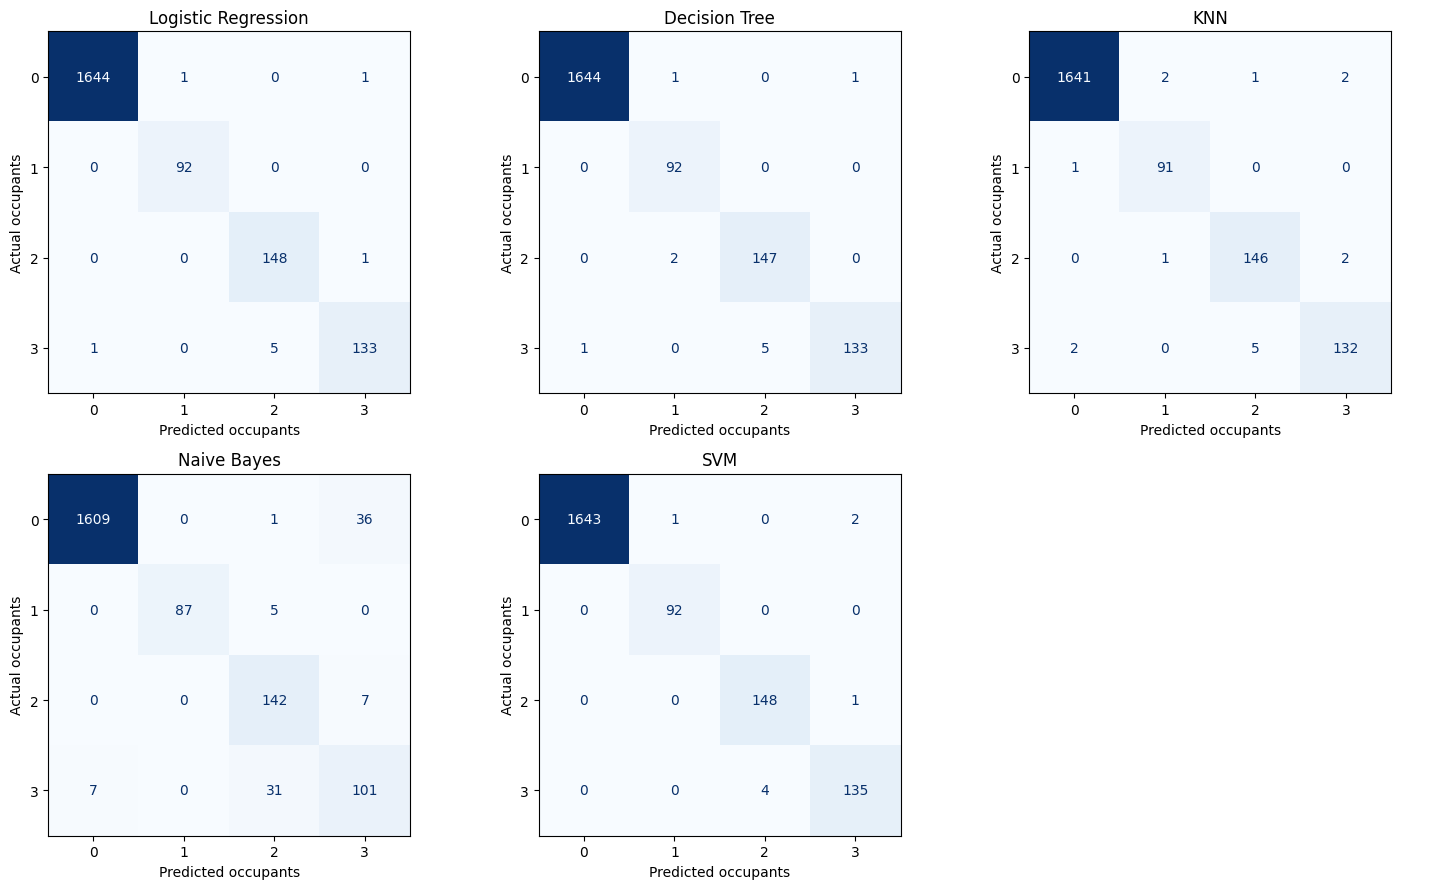

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report

predictions = {name: pipe.predict(X_test) for name, pipe in models.items()}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted occupants")
    ax.set_ylabel("Actual occupants")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [31]:
# Where do the mistakes happen? Split errors into "empty vs occupied" and "wrong head-count"
rows = {}
for name, y_pred in predictions.items():
    yt, yp = y_test.to_numpy(), y_pred
    wrong = yt != yp
    empty_vs_occupied = wrong & ((yt == 0) | (yp == 0))
    rows[name] = {
        "total errors": int(wrong.sum()),
        "empty <-> occupied": int(empty_vs_occupied.sum()),
        "among 1/2/3 people": int((wrong & ~empty_vs_occupied).sum()),
    }
pd.DataFrame(rows).T

,total errors,empty <-> occupied,among 1/2/3 people
Logistic Regression,9,3,6
Decision Tree,10,3,7
KNN,16,8,8
Naive Bayes,87,44,43
SVM,8,3,5


In [32]:
# Naive Bayes calls 36 empty-room rows "3 people". What do those rows look like?
nb_pred = predictions["Naive Bayes"]
empty_as_three = (y_test.to_numpy() == 0) & (nb_pred == 3)
show = ["S1_Temp", "S3_Temp", "S1_Light", "S3_Light", "S5_CO2", "S5_CO2_Slope"]
pd.DataFrame({
    "all empty-room test rows": X_test[y_test == 0][show].median(),
    "empty rows NB labelled 3": X_test[empty_as_three][show].median(),
    "real 3-person test rows": X_test[y_test == 3][show].median(),
}).round(2)

,all empty-room test rows,empty rows NB labelled 3,real 3-person test rows
S1_Temp,25.31,26.06,26.19
S3_Temp,24.88,25.88,25.88
S1_Light,0.00,15.00,149.00
S3_Light,0.00,73.00,180.00
S5_CO2,355.00,837.50,875.00
S5_CO2_Slope,0.00,-1.96,1.94


**Findings**

- For Logistic Regression, Decision Tree and SVM most of the errors are between 1, 2 and 3 people, not empty vs occupied (6 of 9, 7 of 10 and 5 of 8). KNN's 16 errors are split evenly. The most common mistake for these four models is **3 people predicted as 2** (4–5 rows each), which matches the overlapping CO2 boxes for 2 and 3 people.
- **Naive Bayes** behaves differently: 36 empty-room rows are predicted as 3 people and 31 three-person rows as 2. The empty rows it calls "3" have high CO2 (median 838 ppm, close to the real 3-person median), a falling CO2 slope (−1.96) and warm temperatures — a room people have just left. Naive Bayes judges each feature separately and multiplies the likelihoods, so the CO2 and four warm temperature readings outweigh the lower light. The other four models make at most 2 such errors each.

## 14. Classification reports (per class)

In [33]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, y_pred, digits=4))

Logistic Regression
              precision    recall  f1-score   support

           0     0.9994    0.9988    0.9991      1646
           1     0.9892    1.0000    0.9946        92
           2     0.9673    0.9933    0.9801       149
           3     0.9852    0.9568    0.9708       139

    accuracy                         0.9956      2026
   macro avg     0.9853    0.9872    0.9862      2026
weighted avg     0.9956    0.9956    0.9955      2026

Decision Tree
              precision    recall  f1-score   support

           0     0.9994    0.9988    0.9991      1646
           1     0.9684    1.0000    0.9840        92
           2     0.9671    0.9866    0.9767       149
           3     0.9925    0.9568    0.9744       139

    accuracy                         0.9951      2026
   macro avg     0.9819    0.9855    0.9835      2026
weighted avg     0.9951    0.9951    0.9951      2026

KNN
              precision    recall  f1-score   support

           0     0.9982    0.9970    

**Findings:** class 3 (three people) is the hardest class for every model — it has the lowest recall everywhere (SVM 0.9712, LR 0.9568, DT 0.9568, KNN 0.9496, NB 0.7266). Class 1 is the easiest occupied class (recall 1.0 for LR, DT and SVM), which fits the boxplot: one person gives a tight, distinctive light level around 120 lux.

## 15. Save the fitted pipelines

In [34]:
import joblib
from utils import MODEL_FILES

for name, pipe in models.items():
    path = os.path.join("..", "model", MODEL_FILES[name])
    joblib.dump(pipe, path)
    print(f"saved {name:20s} -> {path}")

saved Logistic Regression  -> ../model/logistic_regression.pkl
saved Decision Tree        -> ../model/decision_tree.pkl
saved KNN                  -> ../model/knn.pkl
saved Naive Bayes          -> ../model/naive_bayes.pkl
saved SVM                  -> ../model/svm.pkl


In [35]:
# Reload one model and confirm it predicts exactly as before
reloaded_svm = joblib.load("../model/svm.pkl")
same = np.array_equal(reloaded_svm.predict(X_test), predictions["SVM"])
print("Reloaded SVM gives identical predictions:", same)
assert same

Reloaded SVM gives identical predictions: True


In [36]:
sizes = {name: os.path.getsize(os.path.join("..", "model", f)) / 1024 for name, f in MODEL_FILES.items()}
pd.Series(sizes, name="size (KB)").round(1)

Logistic Regression       2.6
Decision Tree             9.5
KNN                    1078.2
Naive Bayes               3.0
SVM                      94.5
Name: size (KB), dtype: float64

**Findings:** the reloaded SVM gives identical predictions, so the saved files are safe to use in the app. File sizes: Logistic Regression 2.6 KB, Naive Bayes 3.0 KB and Decision Tree 9.5 KB store only coefficients, class statistics or split rules; the SVM (94.5 KB) stores its support vectors; KNN (≈1.1 MB) is the largest because it keeps all 8,103 training rows. All are small enough for GitHub.